# MATH840 Final Project
D. Tkach

We forecast 48 hours of electricity generation. We also give a 95% prediction
interval for each hour. This report uses the fixed final forecast and saved
historical experiments. It does not train or change the model.

In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path('.')
data = pd.read_csv(root / 'train.csv', parse_dates=['ds'])
weather = pd.read_csv(root / 'weather_forecast.csv', parse_dates=['ds'])
submission = pd.read_csv(root / 'TKACH_project.csv')
pred = pd.read_csv(root / 'results/predictions.csv', parse_dates=['origin', 'ds'])
method = json.loads((root / 'results/method.json').read_text())
plan = json.loads((root / 'results/validation_plan.json').read_text())
final_model = method['selected_model']
H = 48
FUTURE = weather['ds']

period_names = {
    'test_2024_autumn': '2024 test',
    'test_2025_autumn': '2025 test',
    'diagnostic_2026_october': '2026 Oct diagnostic'
}
model_names = {
    'Adaptive forecast': 'Final model',
    'Equal ensemble of top two': 'Base ensemble',
    'Seasonal Naive': 'Seasonal Naive'
}
pred['day'] = 1 + (pred['horizon'] - 1) // 24
assert data['ds'].is_unique
assert data['y'].gt(0).all()
assert np.isfinite(pred[['actual', 'forecast', 'lower_95', 'upper_95']]).all().all()
known_actual = data.set_index('ds')['y'].reindex(pred['ds']).to_numpy()
np.testing.assert_allclose(pred['actual'], known_actual, rtol=0, atol=1e-9)
assert hashlib.sha256((root / 'TKACH_project.csv').read_bytes()).hexdigest() == method['forecast_sha256']
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.2})
print('Data loaded. Saved actual values and the fixed CSV were checked.')

## 1. What is in the series?

The history has hourly generation and seven weather variables. There are no
missing hours or missing values. The unit of generation is not given. We keep
the timestamps and units as supplied. Future weather is a forecast. It has no
generation target.

In [2]:
facts = pd.DataFrame({
    'Item': ['History hours', 'First hour', 'Last hour', 'Weather variables',
             'Missing cells', 'Gaps between hours', 'Smallest generation', 'Largest generation'],
    'Value': [len(data), str(data['ds'].min()), str(data['ds'].max()),
              len(weather.columns) - 1, int(data.isna().sum().sum()),
              int(data['ds'].diff().iloc[1:].ne(pd.Timedelta(hours=1)).sum()),
              data['y'].min(), data['y'].max()]
})
display(facts)
yearly = data.groupby(data['ds'].dt.year)['y'].agg(['count', 'mean', 'std'])
yearly.index.name = 'Year'
display(yearly.round(2))

,Item,Value
0,History hours,33480
1,First hour,2023-01-01 01:00:00
2,Last hour,2026-10-27 00:00:00
3,Weather variables,7
4,Missing cells,0
5,Gaps between hours,0
6,Smallest generation,0.7
7,Largest generation,3111.3


,count,mean,std
Year,,,
2023,8759,170.78,122.90
2024,8784,183.86,127.02
2025,8760,291.47,220.43
2026,7177,683.77,620.14


Generation has a daily pattern. Its level and spread also change over time.
The yearly table covers different time spans. In particular, 2026 is not a
full year. The last week is much lower than the week before it.

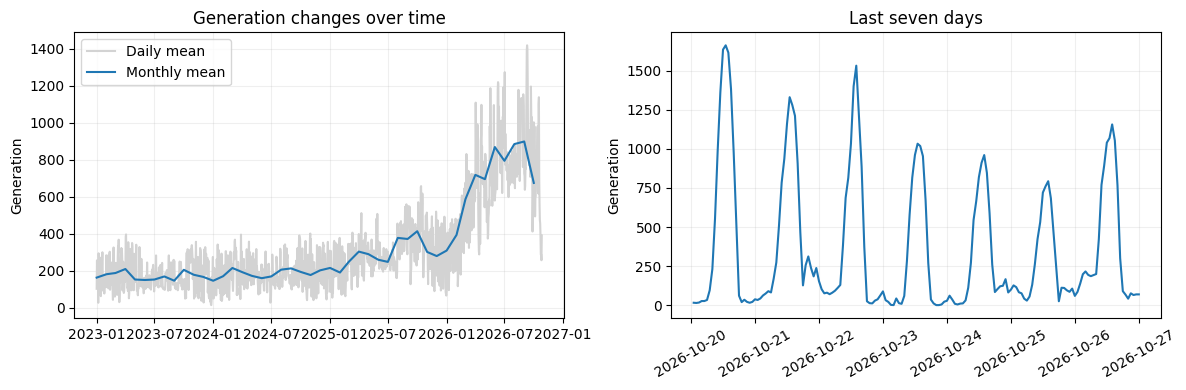

In [3]:
# A full forecasting day starts at 01:00 and ends at 00:00.
day_label = (data['ds'] - pd.Timedelta(hours=1)).dt.floor('D')
daily = data.groupby(day_label)['y'].agg(['mean', 'count'])
daily = daily[daily['count'] == 24]
monthly = daily['mean'].resample('MS').mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(daily.index, daily['mean'], color='lightgray', label='Daily mean')
axes[0].plot(monthly.index, monthly, label='Monthly mean')
axes[0].set(title='Generation changes over time', ylabel='Generation')
axes[0].legend()
recent_week = data.tail(7 * 24)
axes[1].plot(recent_week['ds'], recent_week['y'])
axes[1].set(title='Last seven days', ylabel='Generation')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()
week_ratio = daily['mean'].iloc[-7:].mean() / daily['mean'].iloc[-14:-7].mean()
print(f'Last seven-day mean / previous seven-day mean: {100 * week_ratio:.2f}%')

The next plots use the last 150 days. Wind and cloud cover have links with
generation. These are averages. They do not prove cause. Hour, season and the
changing generation level can affect the results.

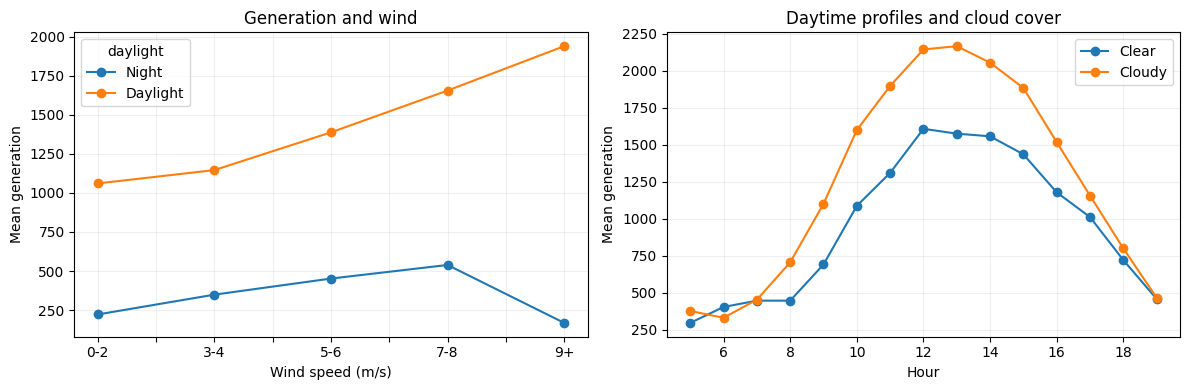

In [4]:
recent = data.tail(150 * 24).copy()
recent['wind_group'] = pd.cut(recent['wind_speed'], [-0.1, 2, 4, 6, 8, 20],
                              labels=['0-2', '3-4', '5-6', '7-8', '9+'])
wind_means = recent.groupby(['wind_group', 'daylight'], observed=False)['y'].mean().unstack()
daytime = recent[recent['daylight'] == 1].copy()
clear = daytime[daytime['cloud_cover'] <= 0.25]
cloudy = daytime[daytime['cloud_cover'] >= 0.75]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
wind_means.rename(columns={0: 'Night', 1: 'Daylight'}).plot(marker='o', ax=axes[0])
axes[0].set(title='Generation and wind', xlabel='Wind speed (m/s)', ylabel='Mean generation')
axes[1].plot(clear.groupby(clear['ds'].dt.hour)['y'].mean(), marker='o', label='Clear')
axes[1].plot(cloudy.groupby(cloudy['ds'].dt.hour)['y'].mean(), marker='o', label='Cloudy')
axes[1].set(title='Daytime profiles and cloud cover', xlabel='Hour', ylabel='Mean generation')
axes[1].legend()
plt.tight_layout()
plt.show()

These patterns led us to use recent daily profiles, level changes, time and
weather. We scale generation using the last 72 known hours. Two small tree
models learn a relative level and a change from the last daily profile. Their
average is the base ensemble. The final model also uses Seasonal Naive as
insurance. Its weight uses errors from eight completed earlier forecasts.
Session 1 is not a component of the new ensemble.

## 2. How did we check the forecast?

Seasonal Naive repeats the last known 24-hour profile for both future days.
We use its original class interval and compare on the same forecast hours.

Training starts every 24 hours. Each start has 48 targets. A training block is
used only when all its targets are earlier than the current forecast. One tree
uses the last year. The other uses all past data. Recent rows get more weight.
Overlapping training targets are not independent new observations.

We chose base models on development data. Interval rules and adaptive weights
used a separate calibration period. The base test job was already running
when the adaptive choice was fixed. We read no test losses before that choice.
We did not choose a model from public leaderboard scores.

In [5]:
blocks = []
for block in plan['development']:
    blocks.append(('Development', block))
blocks.append(('Interval warm-up', plan['calibration_warmup']))
blocks.append(('Calibration', plan['calibration']))
for block in plan['independent_test_blocks']:
    blocks.append(('Test', block))
blocks.append(('Recent diagnostic', plan['recent_diagnostic']))
period_rows = []
for use, block in blocks:
    start = pd.Timestamp(block['start'])
    end = start + pd.Timedelta(days=(block['count'] - 1) * block['step_days'], hours=47)
    period_rows.append({'Use': use, 'First target': str(start), 'Last target': str(end),
                        'Windows': block['count'], 'Step (days)': block['step_days']})
display(pd.DataFrame(period_rows))
print('Training table:', method['training_origin_count'], 'starts,',
      method['training_row_count'], 'rows,', method['feature_count'], 'features.')

,Use,First target,Last target,Windows,Step (days)
0,Development,2023-10-01 01:00:00,2023-11-16 00:00:00,12,4
1,Development,2024-04-01 01:00:00,2024-05-17 00:00:00,12,4
2,Interval warm-up,2024-06-30 01:00:00,2024-08-01 00:00:00,16,2
3,Calibration,2024-08-01 01:00:00,2024-09-18 00:00:00,24,2
4,Test,2024-10-01 01:00:00,2024-11-30 00:00:00,30,2
5,Test,2025-10-01 01:00:00,2025-11-30 00:00:00,30,2
6,Recent diagnostic,2026-10-01 01:00:00,2026-10-27 00:00:00,13,2


Each test block has 30 separate 48-hour windows. We refit using earlier data
at each origin. Earlier test outcomes can enter later fits after they happen.
The model settings stay fixed. October 2026 has 13 windows, but it had already
been studied before. It is a recent diagnostic, not an independent test.

The functions below are copied from the original class notebook. Lower RMSE,
MAPE and Winkler are better. MAPE keeps the original denominator, including
small actual values. We pool errors before taking the square root for RMSE.

In [6]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))

def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)

def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))

def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}

def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")

In [7]:
metric_rows = []
for (period, model, scenario, day), group in pred.groupby(['period', 'model', 'scenario', 'day']):
    values = score(group['actual'].to_numpy(), group['forecast'].to_numpy(),
                   group['lower_95'].to_numpy(), group['upper_95'].to_numpy())
    metric_rows.append({'period': period, 'model': model, 'scenario': scenario, 'day': day,
                        'windows': group['origin'].nunique(), 'hours': len(group), **values})
metrics = pd.DataFrame(metric_rows)

# Check every calculated day score against the saved experiment summary.
reference = pd.read_csv(root / 'results/reference_metrics.csv')
reference = reference[reference['horizon'].isin(['day 1', 'day 2'])].copy()
reference['day'] = reference['horizon'].str[-1].astype(int)
checked = metrics.merge(reference, on=['period', 'model', 'scenario', 'day'],
                         suffixes=('_new', '_saved'), validate='one_to_one')
assert len(checked) == len(metrics)
for name in ['RMSE', 'MAPE', 'Winkler', 'coverage']:
    np.testing.assert_allclose(checked[name + '_new'], checked[name + '_saved'], rtol=1e-9, atol=1e-8)
print('All calculated day scores match the saved results.')

In [8]:
moderate = metrics[(metrics['scenario'] == 'moderate') &
                    metrics['model'].isin([final_model, 'Seasonal Naive'])]
for day in [1, 2]:
    print(f'Day {day}: hours {1 if day == 1 else 25}-{24 if day == 1 else 48}')
    table = moderate[moderate['day'] == day].copy()
    table['period'] = table['period'].map(period_names)
    table['model'] = table['model'].map(model_names)
    table['Coverage (%)'] = 100 * table['coverage']
    display(table[['period', 'model', 'windows', 'hours', 'RMSE', 'MAPE', 'Winkler', 'Coverage (%)']]
            .rename(columns={'period': 'Period', 'model': 'Model', 'MAPE': 'MAPE (%)'})
            .round(2))

,Period,Model,windows,hours,RMSE,MAPE (%),Winkler,Coverage (%)
4,2026 Oct diagnostic,Final model,13,312,240.13,460.51,1047.21,95.51
24,2026 Oct diagnostic,Seasonal Naive,13,312,294.15,429.38,2421.75,70.83
34,2024 test,Final model,30,720,85.77,82.44,429.92,96.25
54,2024 test,Seasonal Naive,30,720,121.78,96.38,521.85,93.75
64,2025 test,Final model,30,720,117.20,89.30,532.04,94.44
84,2025 test,Seasonal Naive,30,720,160.59,114.80,816.88,86.39


,Period,Model,windows,hours,RMSE,MAPE (%),Winkler,Coverage (%)
5,2026 Oct diagnostic,Final model,13,312,273.30,243.73,1205.07,96.15
25,2026 Oct diagnostic,Seasonal Naive,13,312,330.09,257.31,2115.95,83.65
35,2024 test,Final model,30,720,104.02,141.54,455.30,95.00
55,2024 test,Seasonal Naive,30,720,156.17,130.76,568.17,97.50
65,2025 test,Final model,30,720,158.98,162.46,780.83,94.31
85,2025 test,Seasonal Naive,30,720,210.95,205.57,864.48,90.00


The final model has lower day-2 RMSE in both tests. MAPE is worse in the 2024
test. The 2025 interval coverage is below 95%. We do not claim a win in every
metric. The recent diagnostic is shown with its own label.

Historical weather is observed weather. We also test smooth random errors
and positive or negative bias. Day-2 random changes are 1.7 times larger.
These are assumed errors, not old issued weather forecasts.

`observed` is a best-case weather input. `moderate` adds random errors.
`strong` doubles those errors. `bias_high` and `bias_low` add or subtract
fixed errors. For day one, the wind bias is 1 m/s, the temperature bias is
1.5 degrees, and the cloud-cover bias is 0.15. Day-two biases are 1.7 times larger.

In [9]:
stress_rows = []
tests_only = pred[(pred['model'] == final_model) & (pred['day'] == 2) &
                   pred['period'].isin(['test_2024_autumn', 'test_2025_autumn'])]
for scenario, group in tests_only.groupby('scenario'):
    values = score(group['actual'].to_numpy(), group['forecast'].to_numpy(),
                   group['lower_95'].to_numpy(), group['upper_95'].to_numpy())
    stress_rows.append({'Scenario': scenario, 'RMSE': values['RMSE'], 'MAPE (%)': values['MAPE'],
                        'Winkler': values['Winkler'], 'Coverage (%)': 100 * values['coverage']})
display(pd.DataFrame(stress_rows).round(2))

,Scenario,RMSE,MAPE (%),Winkler,Coverage (%)
0,bias_high,142.95,186.01,618.01,94.58
1,bias_low,136.44,136.73,649.37,92.50
2,moderate,134.34,152.00,618.07,94.65
3,observed,131.85,150.00,593.43,95.14
4,strong,142.05,161.32,676.67,91.94


## 3. How good is the interval?

We use errors from the last 16 completed forecasts. We divide errors by a scale
based on the forecast level and recent daily changes. Day one and day two,
and daylight and night, have separate groups. This lets the width change.

Calibration compared symmetric and asymmetric intervals at two quantiles.
It also compared two weather-error pools. We chose the lowest day-2 Winkler
among rules with at least 95% calibration coverage. The selected rule uses
the 95th absolute-error quantile and a stress mixture. Lower bounds stop at zero.

Coverage is the share of actual values inside the interval. Winkler adds the
interval width and 40 times the distance of a miss outside a bound. A wide
interval costs more, but a narrow interval with large misses can cost much more.

In [10]:
rules = pd.read_csv(root / 'results/interval_calibration.csv')
rules['Coverage (%)'] = 100 * rules['coverage']
display(rules[['rule', 'probability', 'pool', 'Winkler', 'Coverage (%)']].round(3))

interval_rows = []
final_moderate = pred[(pred['model'] == final_model) & (pred['scenario'] == 'moderate')].copy()
for (period, day, daylight), group in final_moderate.groupby(['period', 'day', 'daylight']):
    actual = group['actual'].to_numpy()
    low = group['lower_95'].to_numpy()
    high = group['upper_95'].to_numpy()
    interval_rows.append({'Period': period_names[period], 'Day': day,
                           'Hours': 'Daylight' if daylight else 'Night', 'Count': len(group),
                           'Coverage (%)': 100 * np.mean((actual >= low) & (actual <= high)),
                           'Below lower': int(np.sum(actual < low)),
                           'Above upper': int(np.sum(actual > high)),
                           'Mean width': np.mean(high - low)})
display(pd.DataFrame(interval_rows).round(2))

,rule,probability,pool,Winkler,Coverage (%)
0,absolute,0.950,moderate,402.324,96.354
1,absolute,0.975,moderate,462.320,98.090
2,signed,0.950,moderate,432.184,95.312
3,signed,0.975,moderate,481.340,97.917
4,absolute,0.950,moderate+bias_high+bias_low,398.665,96.181
5,absolute,0.975,moderate+bias_high+bias_low,442.967,97.917
6,signed,0.950,moderate+bias_high+bias_low,415.574,95.312
7,signed,0.975,moderate+bias_high+bias_low,444.522,97.396


,Period,Day,Hours,Count,Coverage (%),Below lower,Above upper,Mean width
0,2026 Oct diagnostic,1,Night,185,98.38,0,3,667.52
1,2026 Oct diagnostic,1,Daylight,127,91.34,3,8,1164.89
2,2026 Oct diagnostic,2,Night,185,94.59,4,6,719.03
3,2026 Oct diagnostic,2,Daylight,127,98.43,0,2,1355.13
4,2024 test,1,Night,451,97.56,2,9,332.36
5,2024 test,1,Daylight,269,94.05,8,8,392.75
6,2024 test,2,Night,452,96.02,1,17,331.12
7,2024 test,2,Daylight,268,93.28,6,12,394.04
8,2025 test,1,Night,451,95.12,13,9,421.60
9,2025 test,1,Daylight,269,93.31,7,11,503.86


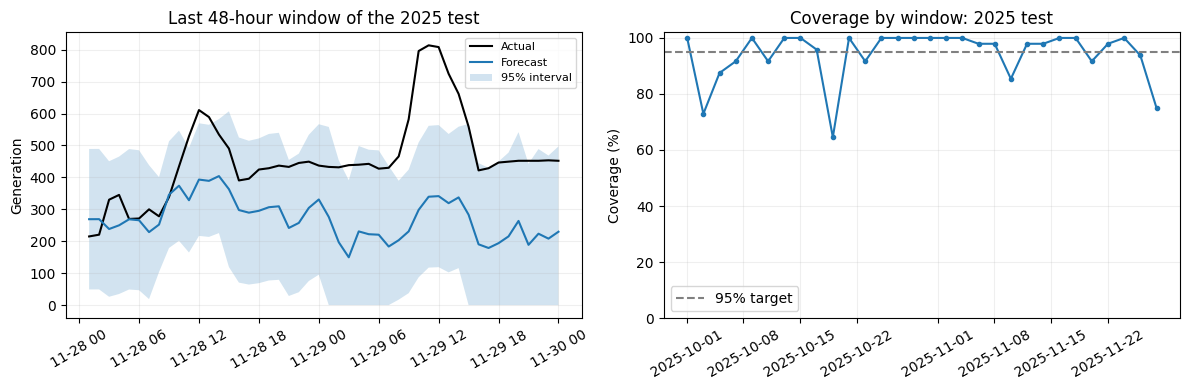

In [11]:
test_2025 = final_moderate[final_moderate['period'] == 'test_2025_autumn'].copy()
last_origin = test_2025['origin'].max()
example = test_2025[test_2025['origin'] == last_origin].sort_values('horizon')
coverage_rows = []
for origin, group in test_2025.groupby('origin'):
    inside = (group['actual'] >= group['lower_95']) & (group['actual'] <= group['upper_95'])
    coverage_rows.append({'origin': origin, 'coverage': 100 * inside.mean()})
window_coverage = pd.DataFrame(coverage_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(example['ds'], example['actual'], color='black', label='Actual')
axes[0].plot(example['ds'], example['forecast'], label='Forecast')
axes[0].fill_between(example['ds'], example['lower_95'], example['upper_95'], alpha=0.2,
                      label='95% interval')
axes[0].set(title='Last 48-hour window of the 2025 test', ylabel='Generation')
axes[0].legend(fontsize=8)
axes[1].plot(window_coverage['origin'], window_coverage['coverage'], marker='o', markersize=3)
axes[1].axhline(95, color='gray', linestyle='--', label='95% target')
axes[1].set(title='Coverage by window: 2025 test', ylabel='Coverage (%)', ylim=(0, 102))
axes[1].legend()
for axis in axes:
    axis.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

Coverage changes between windows. In the 2025 test, day-2 coverage is 94.31%,
below the target. Daylight coverage for that day is only 92.16%. Strong weather
errors also lower coverage. Weather bias and a new generation regime can cause misses.
Errors are linked over time, so this method does not give an exact coverage
guarantee. A 95% interval for one hour is also not a 95% promise for all 48 hours.

## 4. What is left, and what did not work?

A residual is actual generation minus the forecast. Positive errors mean the
forecast was too low. Negative errors mean it was too high. The next plot uses
only the two tests, not the unknown 48-hour target.

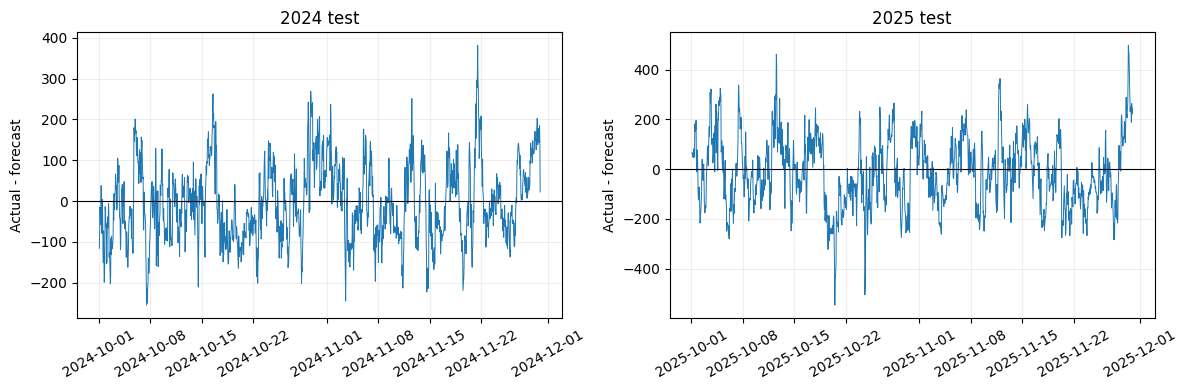

,Period,Mean error,Error link at lag 1,Error link at lag 24
0,2024 test,-4.312,0.888,0.124
1,2025 test,-13.894,0.902,0.189


,ds,actual,forecast,error
44483,2025-10-20 12:00:00,394.6,940.84,-546.24
44965,2025-10-24 14:00:00,482.2,986.82,-504.62
49281,2025-11-29 10:00:00,796.0,298.42,497.58
49282,2025-11-29 11:00:00,813.8,339.52,474.28
44966,2025-10-24 15:00:00,427.4,899.93,-472.53


In [12]:
residuals = final_moderate[final_moderate['period'].isin(['test_2024_autumn', 'test_2025_autumn'])].copy()
residuals['error'] = residuals['actual'] - residuals['forecast']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, period in zip(axes, ['test_2024_autumn', 'test_2025_autumn']):
    group = residuals[residuals['period'] == period].sort_values('ds')
    axis.plot(group['ds'], group['error'], linewidth=0.7)
    axis.axhline(0, color='black', linewidth=0.8)
    axis.set(title=period_names[period], ylabel='Actual - forecast')
    axis.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

error_rows = []
for period, group in residuals.groupby('period'):
    group = group.sort_values('ds')
    error_rows.append({'Period': period_names[period], 'Mean error': group['error'].mean(),
                        'Error link at lag 1': group['error'].autocorr(1),
                        'Error link at lag 24': group['error'].autocorr(24)})
display(pd.DataFrame(error_rows).round(3))
display(residuals.assign(absolute_error=residuals['error'].abs())
        .nlargest(5, 'absolute_error')[['ds', 'actual', 'forecast', 'error']].round(2))

Some errors stay large for several hours. We have not explained every change.
Small night values can also make MAPE very large. We kept all such values.

We screened nine settings on the same eight development windows. The table
below shows point scores only. We checked intervals after choosing point models.

In [13]:
screen = pd.read_csv(root / 'results/screen_scores.csv')
screen = screen[(screen['scenario'] == 'moderate') & (screen['horizon'] == 'day 2')]
screen_table = screen.groupby('model').agg(Windows=('MSE', 'size'), MSE=('MSE', 'mean'),
                                           MAPE=('MAPE', 'mean')).reset_index()
screen_table['RMSE'] = np.sqrt(screen_table['MSE'])
display(screen_table[['model', 'Windows', 'RMSE', 'MAPE']]
        .rename(columns={'model': 'Model', 'MAPE': 'MAPE (%)'}).sort_values('RMSE').round(2))

development = pd.read_csv(root / 'results/development_scores.csv')
development = development[(development['scenario'] == 'moderate') & (development['horizon'] == 'day 2')]
development_table = development.groupby('model').agg(Windows=('MSE', 'size'), MSE=('MSE', 'mean'),
                                                     MAPE=('MAPE', 'mean')).reset_index()
development_table['RMSE'] = np.sqrt(development_table['MSE'])
print('Larger development check: 24 windows')
display(development_table[['model', 'Windows', 'RMSE', 'MAPE']]
        .rename(columns={'model': 'Model', 'MAPE': 'MAPE (%)'}).sort_values('RMSE').round(2))

,Model,Windows,RMSE,MAPE (%)
7,HGB normalized 365d,8,101.02,141.47
0,HGB absolute 150d,8,101.44,154.69
8,Ridge delta all history,8,102.61,133.71
1,HGB delta all history,8,104.61,129.33
5,HGB log normalized,8,105.42,128.07
6,HGB log ratio 365d,8,106.47,108.94
2,HGB delta augmented,8,108.00,151.89
4,HGB delta recent 90d,8,111.85,143.64
3,HGB delta no weather,8,117.82,147.26
9,Seasonal Naive,8,151.04,119.25


,Model,Windows,RMSE,MAPE (%)
0,Equal ensemble of top two,24,102.48,105.22
2,HGB log normalized,24,102.64,100.01
1,HGB delta all history,24,105.78,111.86
3,Origin-time Naive fallback,24,108.73,101.92
4,Ridge delta all history,24,118.53,102.19
5,Seasonal Naive,24,138.46,126.40


Removing weather was not a reliable improvement. The recent-only and
absolute-target trees did not give the best balance. Ridge looked good in the
small screen, but was weaker in the larger check and in weather-bias tests.
A fixed rule that moved toward Naive after level changes did not win selection.

The adaptive insurance rule improved calibration scores. The base ensemble
then scored better on the tests. We kept the choice made before reading test
losses. We do not claim that adaptive insurance improved the base model on test.

In [14]:
controls = metrics[(metrics['scenario'] == 'moderate') & (metrics['day'] == 2)].copy()
controls['Period'] = controls['period'].map(period_names)
controls['Model'] = controls['model'].map(model_names)
controls['Coverage (%)'] = 100 * controls['coverage']
display(controls[['Period', 'Model', 'RMSE', 'MAPE', 'Winkler', 'Coverage (%)']]
        .rename(columns={'MAPE': 'MAPE (%)'}).round(2))

,Period,Model,RMSE,MAPE (%),Winkler,Coverage (%)
5,2026 Oct diagnostic,Final model,273.30,243.73,1205.07,96.15
15,2026 Oct diagnostic,Base ensemble,271.37,231.80,1110.68,96.47
25,2026 Oct diagnostic,Seasonal Naive,330.09,257.31,2115.95,83.65
35,2024 test,Final model,104.02,141.54,455.30,95.00
45,2024 test,Base ensemble,99.56,136.87,414.97,95.56
55,2024 test,Seasonal Naive,156.17,130.76,568.17,97.50
65,2025 test,Final model,158.98,162.46,780.83,94.31
75,2025 test,Base ensemble,152.37,143.81,728.26,94.17
85,2025 test,Seasonal Naive,210.95,205.57,864.48,90.00


LightGBM and CatBoost were not run. They were not installed, and network
installation was blocked. Pretrained models were left out because permission
for external training data was not clear. No scores for these models are invented.

The main limits are unknown weather forecast errors, sudden level changes and
large night percentage errors. We do not have a new independent recent test.
The October result does not show a large improvement over Session 1. Historical
gains do not guarantee a win on the private hours.

A useful next step is to collect real issued weather forecasts. We would also
test a simple night model and interval rules in a new period. We would not use
the opened test results to claim a fresh independent test.

ChatGPT helped with planning and task analysis. Codex helped write and check
the code, compare models and prepare this report. The tables include failed trials.

In [15]:
check_submission(submission)
assert np.isfinite(submission[['forecast', 'lower_95', 'upper_95']]).all().all()
assert hashlib.sha256((root / 'TKACH_project.csv').read_bytes()).hexdigest() == method['forecast_sha256']
print('Final CSV unchanged. The notebook did not train or change a model.')